In [1]:
# Review Evaluator

In [2]:
from langchain_groq import ChatGroq
from langgraph.graph import StateGraph, START, END
from langchain_core.prompts import PromptTemplate
from dotenv import load_dotenv
from pydantic import BaseModel, Field
from typing import TypedDict, Annotated, Literal, List
from langchain_core.output_parsers import StrOutputParser, JsonOutputParser
import yagmail

In [3]:
load_dotenv()

True

In [4]:
pos_rev="These headphones exceeded my expectations. The sound quality is crisp, with deep bass and clear highs, and the noise cancellation works flawlessly even in crowded environments. The battery life easily lasts through long workdays, and the lightweight design makes them comfortable for extended use. Pairing with devices was seamless, and the build feels premium. A fantastic purchase that I’d recommend to anyone who values immersive audio."

In [5]:
neg_rev="The seafood platter was a major disappointment. The shrimp tasted rubbery, the fish was bland, and the fries were soggy. To make matters worse, the service was painfully slow, and the staff seemed indifferent to complaints. For the price charged, I expected fresh flavors and at least a hint of care in preparation. Sadly, I left hungry and frustrated — definitely not worth a revisit."

In [6]:
class Analysis(BaseModel):
    topic: Annotated[str,Field(description='Main topic at which the negative review is pointing. For example, bad food, poor service, etc')]
    feelings: Annotated[List[str],Field(description='list of feelings that the customer is feeling as per the feedback')]
    

class RevState(TypedDict):
    review: Annotated[str,Field(description='Review of the customer')]
    email: Annotated[str,Field(description='email id of the curtomer')]
    sentiment: Annotated[Literal['Positive','Negative'],Field(description='Sentiment of the review: Positive or Negative')]
    neg_feelings_analysis: Annotated[Analysis,Field(description='Analysis')]
    email_subject: Annotated[str,Field(description='Subject of the email sent')]
    email_body: Annotated[str,Field(description='body of the email sent')]
    

In [7]:
model = ChatGroq(model ='openai/gpt-oss-20b')


In [8]:
def get_sentiment(state:RevState)->RevState:
    template1 = PromptTemplate(
        template = 'Tell the sentiment of the below review in one word, Negative or Positive. \n Review -> {review}',
        input_variables=['review']
    )
    chain = template1 | model
    res = chain.invoke({'review':state['review']})
    state['sentiment']=res.content
    return state

In [9]:
def check_sentiment(state:RevState)->str:
    if state['sentiment']=='Positive':
        return 'positive_flow'
    return 'neg_analysis'

In [10]:
def get_analysis(state:RevState)->RevState:
    parser1 = JsonOutputParser(pydatic_object=Analysis)
    template2 = PromptTemplate(
        template='Analyse the review below as stated and generate topic string and feelings list: {format_instructions} \n Review ->{review}',
        input_variables=['review'],
        partial_variables={'format_instructions':parser1.get_format_instructions()}
    )
    chain = template2 | model | parser1
    result = chain.invoke({'review':state['review']})
    state['neg_feelings_analysis']=result
    return state

In [11]:
class MailOutput(BaseModel):
    subject: Annotated[str,Field(description='The subject of the mail')]
    body: Annotated[str,Field(description='The content of the mail')]

In [12]:
def get_neg(state:RevState)->RevState:
    to = state['email']
    parser3 = JsonOutputParser(pydantic_object=MailOutput)
    template4 = PromptTemplate(
        template='For the below Negative review and the analysis of it, write a good subject and email to send to the customer: {format_instructions} \n Review ->{review} \n Analysis -> {analysis}',
        input_variables=['review','analysis'],
        partial_variables={'format_instructions':parser3.get_format_instructions()}
    )
    chain = template4 | model | parser3
    result = chain.invoke({'review':state['review'],'analysis':state['neg_feelings_analysis']})
    yag=yagmail.SMTP('nitinkumarbaranawal@gmail.com','wvsx ezal uoph upeh')
    yag.send(
        to=to,
        subject=result['subject'],
        contents=result['body']
    )
    state['email_subject']=result['subject']
    state['email_body']=result['body']
    return state

In [13]:
def get_pos(state:RevState)->RevState:
    to = state['email']
    parser2 = JsonOutputParser(pydantic_object=MailOutput)
    template3 = PromptTemplate(
        template='For the below Positive review, write a good subject and email to send to the customer: \n {format_instructions} \n Review ->{review}',
        input_variables=['review'],
        partial_variables={'format_instructions':parser2.get_format_instructions()}
    )
    chain = template3 | model | parser2
    result = chain.invoke({'review':state['review']})
    yag=yagmail.SMTP('nitinkumarbaranawal@gmail.com','wvsx ezal uoph upeh')
    yag.send(
        to=to,
        subject=result['subject'],
        contents=result['body']
    )
    state['email_subject']=result['subject']
    state['email_body']=result['body']
    return state

In [14]:
graph = StateGraph(RevState)

In [15]:
# nodes
graph.add_node('get_sentiment',get_sentiment)
graph.add_node('positive_flow',get_pos)
graph.add_node('negative_flow',get_neg)
graph.add_node('neg_analysis',get_analysis)
graph.add_conditional_edges('get_sentiment',check_sentiment,{'positive_flow':'positive_flow','neg_analysis':'neg_analysis'})
# edges
graph.add_edge(START,'get_sentiment')

graph.add_edge('neg_analysis',"negative_flow")
graph.add_edge('negative_flow',END)
graph.add_edge('positive_flow',END)






In [16]:
app = graph.compile()

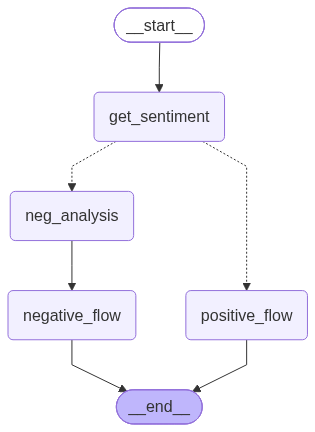

In [17]:
from IPython.display import Image
Image(app.get_graph().draw_mermaid_png())

In [ ]:
app.invoke({'review':neg_rev,'email':'nitinbaranawal24@gmail.com'})